# Statistical vs. Machine Learning Methods for Financial Forecasting

## 1. Introduction

This study compares statistical and machine learning methods for predicting next-day SPY ETF log returns using historical market data.


### 1.1 Research Question
**Research question:** Do nonlinear machine learning methods improve out-of-sample forecasting accuracy relative to traditional statistical benchmarks?

### 1.2 Forecasting Approaches
Six forecasting methods are compared:

* Historical mean benchmark
* Ordinary least squares
* Ridge regression
* LASSO regression
* Random forest regression
* Gradient boosting regression

## 2. Data and Exploratory Analysis

### 2.1 Data Source and Description

We use daily historical price and trading volume data for the SPDR S&P 500 ETF Trust (SPY), obtained through the yfinance Python package. The dataset covers January 4, 2010, through September 30, 2026, and contains 4,211 trading-day observations.

The dataset includes daily opening, high, low, and closing prices, along with trading volume. Prices are adjusted for stock splits and dividends using auto_adjust=True.

SPY is selected as a highly liquid ETF tracking the S&P 500 Index, providing a single-asset setting for evaluating short-horizon forecasting methods.

The analysis uses daily adjusted closing prices to construct returns, while historical price and volume information is used to develop predictive features.

In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

spy = pd.read_csv(
    "data/spy.csv",
    index_col="Date",
    parse_dates=True
)

spy.head()


,Close,High,Low,Open,Volume
Date,,,,,
2010-01-04,84.368950,84.413615,83.014044,83.654275,118944600
2010-01-05,84.592308,84.629533,84.011635,84.316864,111579900
2010-01-06,84.651871,84.860317,84.443424,84.510423,116074400
2010-01-07,85.009216,85.113439,84.257316,84.495541,131091100
2010-01-08,85.292084,85.329309,84.614634,84.785855,126402800


### 2.2 Daily Log Returns
We define the daily log return as

$$
r_t = \log\left(\frac{P_t}{P_{t-1}}\right),
$$

where $P_t$ denotes the adjusted closing price on trading day $t$.

Log returns are used instead of raw prices because they measure relative price changes, are additive across time, and are generally more suitable for statistical modeling of financial time series.

In [86]:
# Calculate daily log returns
spy["return"] = np.log(spy["Close"]).diff()
# or alternatively: spy["return"] = np.log(spy["Close"] / spy["Close"].shift(1))
# spy["Close"].diff(1)  # Today minus yesterday
# spy["Close"].diff(5)  # Today minus 5 trading days ago

# Inspect the first observations
spy[["Close", "return"]].head()

,Close,return
Date,,
2010-01-04,84.368950,NaN
2010-01-05,84.592308,0.002644
2010-01-06,84.651871,0.000704
2010-01-07,85.009216,0.004212
2010-01-08,85.292084,0.003322


### 2.3 Time Series Visualization
The time-series visualizations suggest that large positive and negative daily returns tend to occur during the same periods of market turbulence. This pattern is consistent with volatility clustering, where the magnitude of returns exhibits temporal dependence even when the direction of returns is less predictable.

These observations motivate including historical volatility measures as potential predictors in the forecasting models.

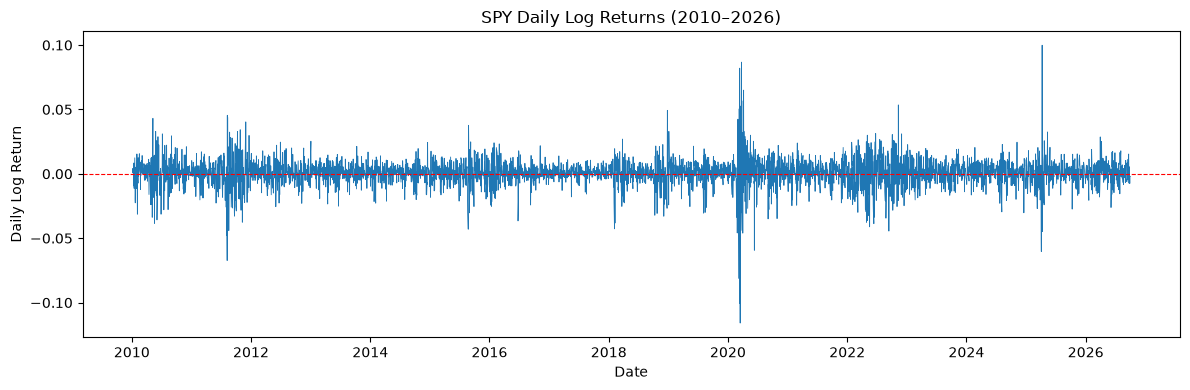

In [87]:
## plotting these daily returns over time
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.plot(spy.index, spy["return"], linewidth=0.6)

plt.axhline(0, color="red", linestyle="--", linewidth=0.8)

plt.title("SPY Daily Log Returns (2010–2026)")
plt.xlabel("Date")
plt.ylabel("Daily Log Return")

plt.tight_layout()
plt.show()

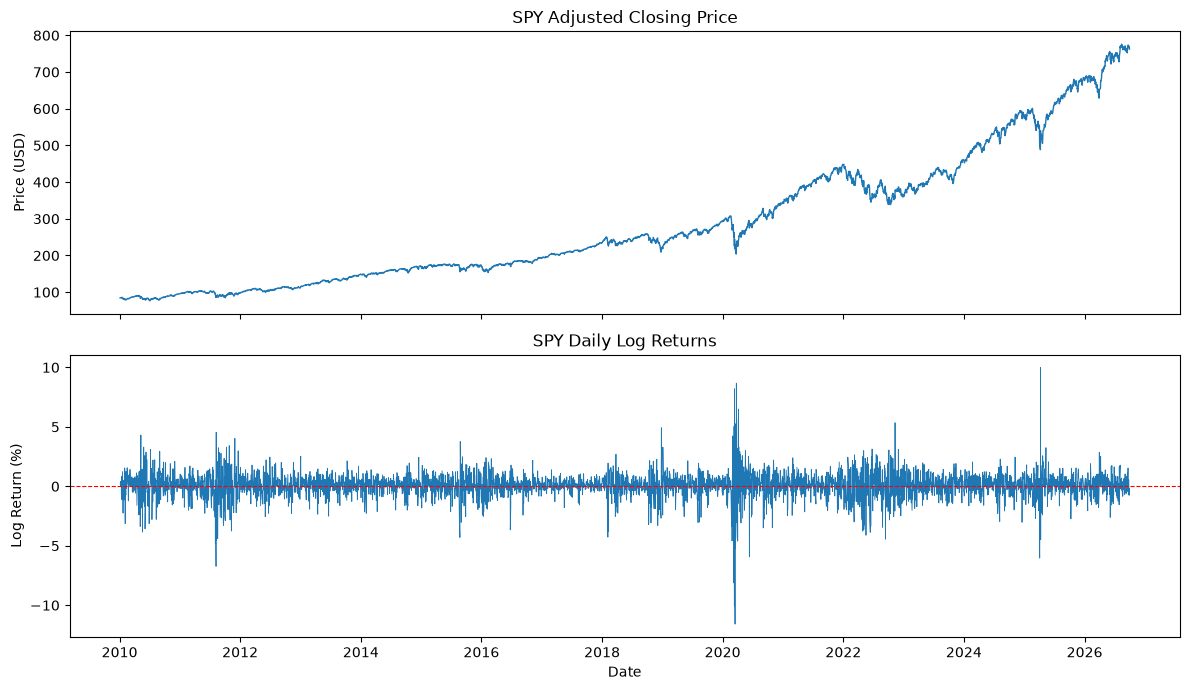

In [88]:
## comparing this against the raw adjusted closing price: 
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# Plot 1: Adjusted closing prices
axes[0].plot(spy.index, spy["Close"], linewidth=1)
axes[0].set_title("SPY Adjusted Closing Price")
axes[0].set_ylabel("Price (USD)")

# Plot 2: Daily log returns
axes[1].plot(spy.index, spy["return"] * 100, linewidth=0.6)
axes[1].axhline(0, color="red", linestyle="--", linewidth=0.8)
axes[1].set_title("SPY Daily Log Returns")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Log Return (%)")

plt.tight_layout()
plt.show()

### 2.4 Descriptive Statistics

First, investingating the points of big dips/ jumps

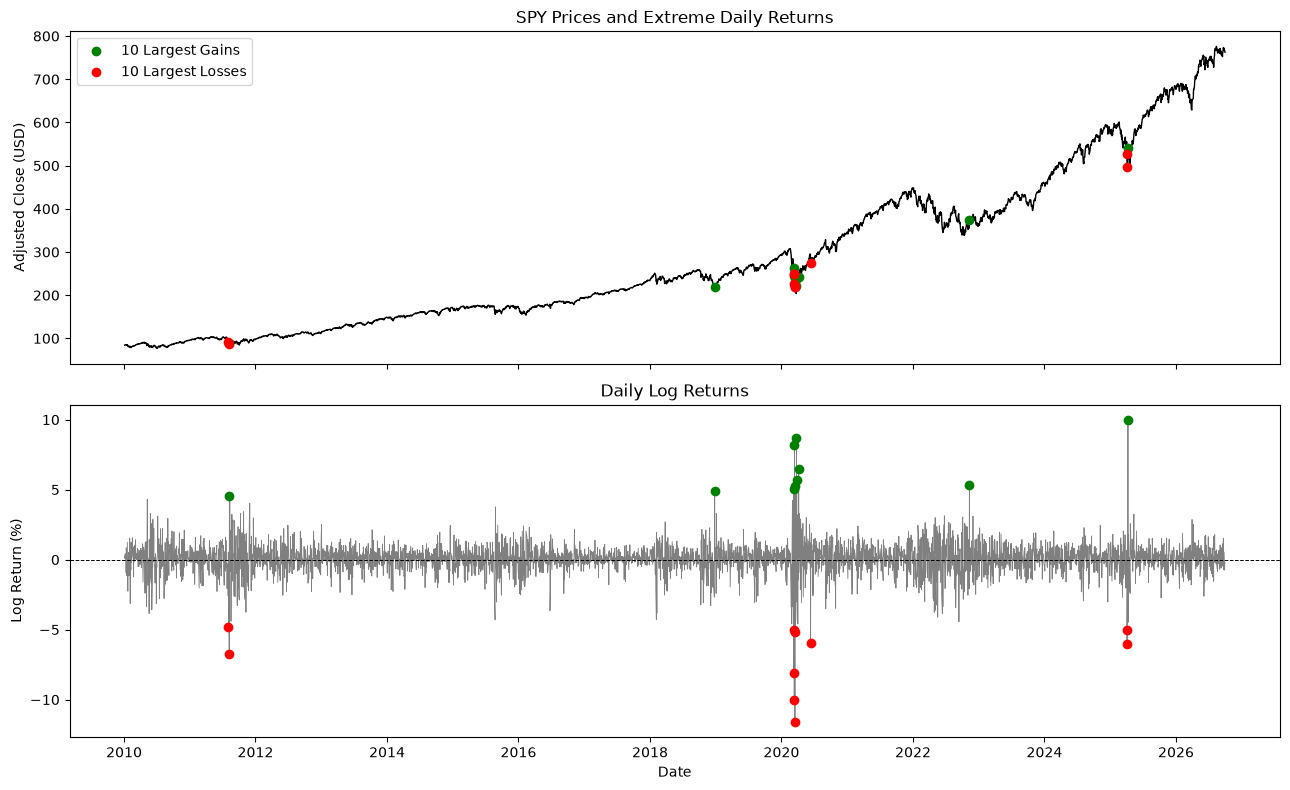

In [89]:
# Identify the 10 largest daily gains and losses
largest_gains = spy.nlargest(10, "return")
largest_losses = spy.nsmallest(10, "return")

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

# Top: Adjusted closing price
axes[0].plot(spy.index, spy["Close"], color="black", linewidth=1)

axes[0].scatter(
    largest_gains.index, largest_gains["Close"],
    color="green", label="10 Largest Gains", zorder=3
)
axes[0].scatter(
    largest_losses.index, largest_losses["Close"],
    color="red", label="10 Largest Losses", zorder=3
)

axes[0].set_title("SPY Prices and Extreme Daily Returns")
axes[0].set_ylabel("Adjusted Close (USD)")
axes[0].legend()

# Bottom: Daily log returns
axes[1].plot(spy.index, spy["return"] * 100,
             color="gray", linewidth=0.6)

axes[1].scatter(
    largest_gains.index, largest_gains["return"] * 100,
    color="green", zorder=3
)
axes[1].scatter(
    largest_losses.index, largest_losses["return"] * 100,
    color="red", zorder=3
)

axes[1].axhline(0, color="black", linestyle="--", linewidth=0.7)
axes[1].set_title("Daily Log Returns")
axes[1].set_ylabel("Log Return (%)")
axes[1].set_xlabel("Date")

plt.tight_layout()
plt.show()

In [90]:
# Descriptive statistics of daily log returns
returns = spy["return"].dropna()

summary = pd.Series({
    "Mean": returns.mean(),
    "Std. Dev.": returns.std(),
    "Median": returns.median(),
    "Skewness": returns.skew(),
    "Excess Kurtosis": returns.kurt(),
    "Minimum": returns.min(),
    "Maximum": returns.max()
})

display(summary.to_frame("Value").round(5))

,Value
Mean,0.00052
Std. Dev.,0.01076
Median,0.00069
Skewness,-0.55434
Excess Kurtosis,12.42463
Minimum,-0.11589
Maximum,0.09986


The largest positive and negative returns appear to cluster during the same periods of market turbulence. 

In [91]:
extreme = pd.concat([largest_gains, largest_losses])
extreme = extreme.sort_index()

display(
    extreme[["Close", "return"]]
    .assign(return_pct=lambda x: x["return"] * 100)
    [["Close", "return_pct"]]
    .round(3)
)

,Close,return_pct
Date,,
2011-08-04,92.137,-4.797
2011-08-08,86.007,-6.734
2011-08-09,90.007,4.545
2018-12-26,219.682,4.929
2020-03-09,249.347,-8.131
2020-03-10,262.249,5.045
2020-03-11,249.465,-4.998
2020-03-12,225.597,-10.057
2020-03-13,244.882,8.203


In [92]:
## creating a function to select any date range:
def plot_market_period(spy, start, end):
    period = spy.loc[start:end]

    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

    # Adjusted closing prices
    axes[0].plot(period.index, period["Close"], color="black")
    axes[0].set_title(f"SPY Prices: {start} to {end}")
    axes[0].set_ylabel("Adjusted Close (USD)")

    # Daily returns
    axes[1].bar(
        period.index,
        period["return"] * 100,
        color=[
            "green" if r >= 0 else "red"
            for r in period["return"]
        ]
    )

    axes[1].axhline(0, color="black", linewidth=0.7)
    axes[1].set_ylabel("Daily Log Return (%)")
    axes[1].set_xlabel("Date")

    plt.tight_layout()
    plt.show()


Examining the 2011 market turmoil, the 2020 COVID-19 crash, and the 2022 bear market.

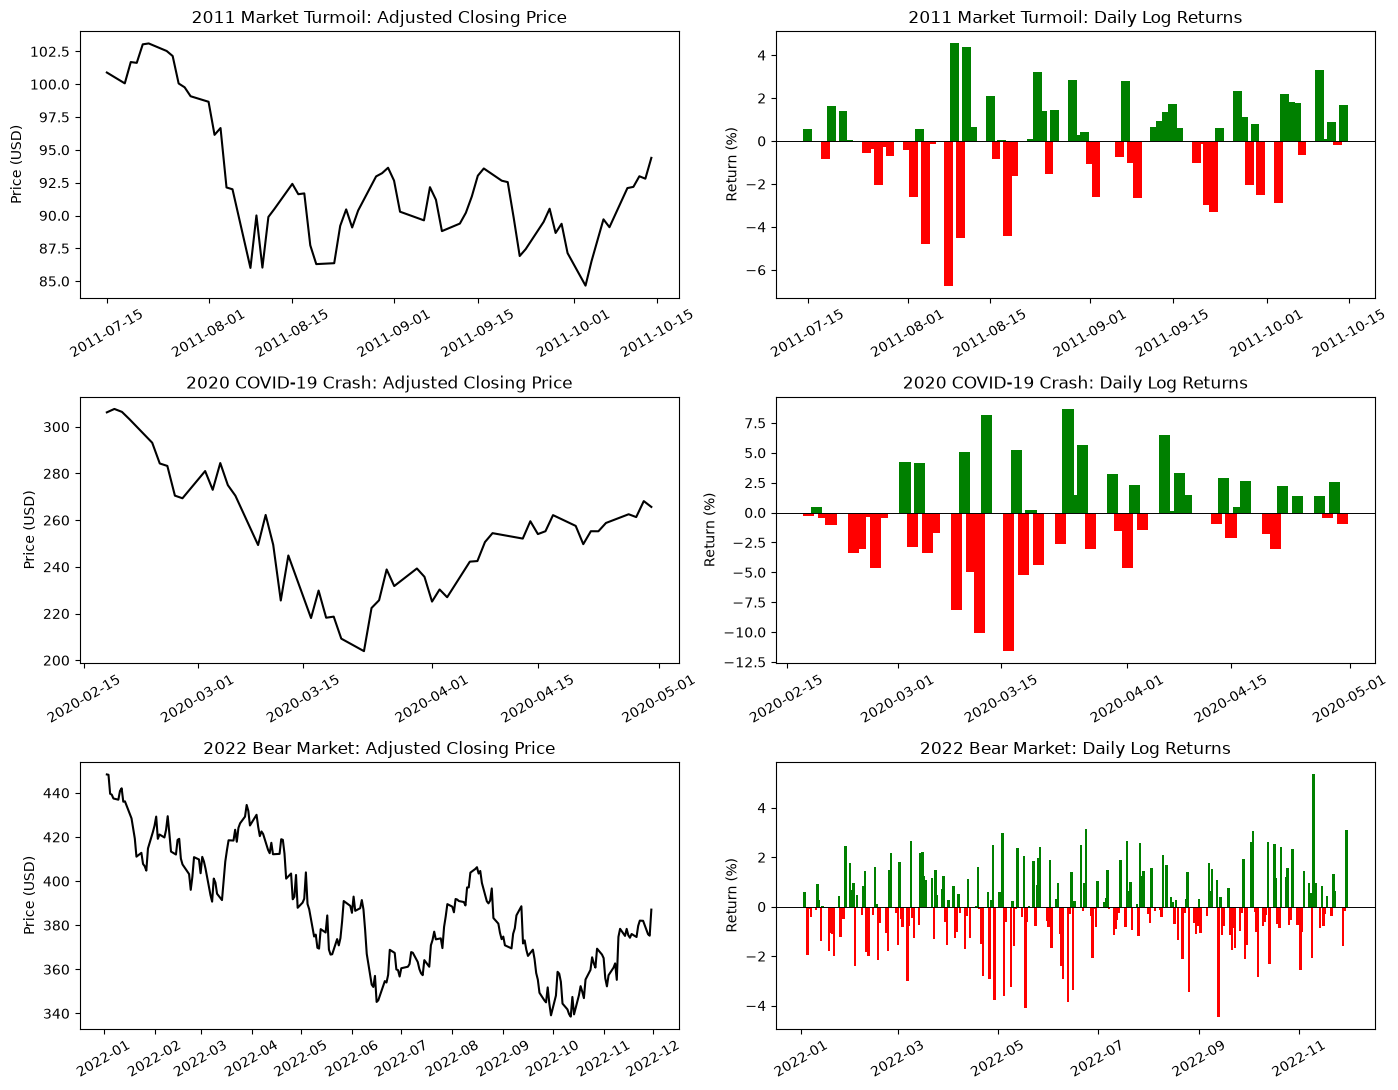

In [93]:
periods = {
    "2011 Market Turmoil": ("2011-07-15", "2011-10-15"),
    "2020 COVID-19 Crash": ("2020-02-15", "2020-04-30"),
    "2022 Bear Market": ("2022-01-01", "2022-11-30")
}

fig, axes = plt.subplots(3, 2, figsize=(14, 11))

for i, (name, (start, end)) in enumerate(periods.items()):
    period = spy.loc[start:end]

    # Left: adjusted closing price
    axes[i, 0].plot(period.index, period["Close"], color="black")
    axes[i, 0].set_title(f"{name}: Adjusted Closing Price")
    axes[i, 0].set_ylabel("Price (USD)")

    # Right: daily log returns
    axes[i, 1].bar(
        period.index,
        period["return"] * 100,
        color=["green" if r >= 0 else "red"
               for r in period["return"]],
        width=1.5
    )
    axes[i, 1].axhline(0, color="black", linewidth=0.7)
    axes[i, 1].set_title(f"{name}: Daily Log Returns")
    axes[i, 1].set_ylabel("Return (%)")

    for ax in axes[i]:
        ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

Computing the volatility in each period: 

In [94]:
for name, (start, end) in periods.items():
    r = spy.loc[start:end, "return"].dropna()

    print(f"{name}")
    print(f"  Mean daily return: {r.mean()*100:.3f}%")
    print(f"  Daily volatility:  {r.std()*100:.3f}%")
    print(f"  Largest daily gain: {r.max()*100:.2f}%")
    print(f"  Largest daily loss: {r.min()*100:.2f}%")
    print()

2011 Market Turmoil
  Mean daily return: -0.094%
  Daily volatility:  2.177%
  Largest daily gain: 4.55%
  Largest daily loss: -6.73%

2020 COVID-19 Crash
  Mean daily return: -0.278%
  Daily volatility:  4.114%
  Largest daily gain: 8.67%
  Largest daily loss: -11.59%

2022 Bear Market
  Mean daily return: -0.061%
  Daily volatility:  1.560%
  Largest daily gain: 5.35%
  Largest daily loss: -4.45%



### 2.6 Distribution of Returns

## 3. Feature Engineering

### 3.1 Prediction Target

### 3.2 Lagged Returns

### 3.3 Rolling Volatility and Momentum

### 3.4 Additional Predictors

## 4. Experimental Design

### 4.1 Chronological Data Split

### 4.2 Time-Series Cross-Validation

### 4.3 Preventing Look-Ahead Bias

## 5. Forecasting Models

### 5.1 Historical Mean Benchmark

### 5.2 Ordinary Least Squares

### 5.3 Ridge and LASSO Regression

### 5.4 Random Forest

### 5.5 Gradient Boosting

## 6. Out-of-Sample Evaluation

### 6.1 Performance Metrics

### 6.2 Model Comparison

### 6.3 Prediction Diagnostics

## 7. Discussion and Conclusions

### 7.1 Main Findings

### 7.2 Limitations

### 7.3 Conclusion